# Telco Customer Churn Prediction — Model Development

This notebook develops and evaluates machine learning models to predict whether a telecom customer will leave (**Churn = Yes**) or stay (**Churn = No**). It covers data inspection, cleaning, preprocessing, seven-model comparison, hyperparameter tuning, final evaluation, and model export for the Streamlit application.

**Business goal:** Identify as many customers at risk of leaving as possible, while understanding the trade-off between recall and false alarms.

In [181]:
# !pip install matplotlib
# !pip install seaborn

In [182]:
import numpy as np
import pandas as pd

from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

pd.set_option("display.max_columns", None) # do not hide any columns every time we run it

## 1. Load and inspect the dataset

Load the Telco Customer Churn CSV and inspect its shape, sample records, and data types. The following checks look for hidden blank strings, duplicate rows, and class imbalance. These checks are important because missing values can be stored as whitespace rather than as `NaN`.

In [183]:
data_path = Path("..") / "dataset" / "Telco-Customer-Churn.csv"

df = pd.read_csv(data_path)

print("Dataset Shape:", df.shape)

display(df.head())

df.info()

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [184]:
# Check empty strings and whitespace-only values
hidden_missing = df.select_dtypes(include="object").apply(
    lambda col: col.str.fullmatch(r"\s*").fillna(False).sum()
)

print(hidden_missing)

customerID           0
gender               0
Partner              0
Dependents           0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
TotalCharges        11
Churn                0
dtype: int64


In [185]:
# Count duplicated rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [186]:
df.head(2)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No


In [187]:
# Display column data types
print(df.dtypes)

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [188]:
# Count customers in each class
print(df["Churn"].value_counts())

# Calculate percentages
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


## 2. Clean the data

`TotalCharges` is initially stored as text because some rows contain blank or whitespace-only values. Convert it to numeric with `errors="coerce"`, examine the resulting missing entries, and fill them with `0` for customers whose tenure is zero. Then verify missing values, duplicates, and whitespace in categorical fields.

In [189]:
print(hidden_missing[hidden_missing > 0])

TotalCharges    11
dtype: int64


In [190]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [191]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

In [192]:
print("Missing values:", df["TotalCharges"].isnull().sum())

Missing values: 11


In [193]:
display(df[df["TotalCharges"].isnull()])

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [194]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [195]:
print("Missing values:", df.isnull().sum().sum())

print("TotalCharges dtype:", df["TotalCharges"].dtype)

print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
TotalCharges dtype: float64
Duplicate rows: 0


In [196]:
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_cols = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

Categorical columns: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']
Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [197]:
# Trim whitespace from all categorical values
for col in categorical_cols:
    df[col] = df[col].str.strip()

# Verify that no leading or trailing whitespace remains
for col in categorical_cols:
    print(f"{col}: {df[col].dropna().eq(df[col].dropna().str.strip()).all()}")

customerID: True
gender: True
Partner: True
Dependents: True
PhoneService: True
MultipleLines: True
InternetService: True
OnlineSecurity: True
OnlineBackup: True
DeviceProtection: True
TechSupport: True
StreamingTV: True
StreamingMovies: True
Contract: True
PaperlessBilling: True
PaymentMethod: True
Churn: True


**Cleaning check:** After conversion and whitespace handling, the dataset is ready for feature preparation. The following cells verify that the cleaning steps worked; do not assume data quality without checking their outputs.

### Scope of exploratory analysis

This notebook focuses on the assignment’s classification workflow rather than extensive exploratory data analysis (EDA). Basic inspections—including data types, missing values, duplicates, and churn-class distribution—are included. A deeper EDA could help explain which customer characteristics are associated with churn, but is not required for this implementation.

## 3. Define features and target

- **Features (`X`):** All predictors except `customerID` and `Churn`. Customer ID is an identifier, not a useful predictive measurement.
- **Target (`y`):** Convert `Churn` to numeric labels: `No → 0` (stay), `Yes → 1` (leave).

The positive class is **1 (churn)**, so precision, recall, and F1-score later refer to customers who leave.

In [198]:
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Missing target values:", y.isna().sum())

Features shape: (7043, 19)
Target shape: (7043,)
Missing target values: 0


## 4. Split into training and test sets

Use an **80% training / 20% test** split. `stratify=y` maintains approximately the same churn proportion in both sets, while `random_state=48` makes the split reproducible. The test set is reserved for the final evaluation and should not guide hyperparameter selection.

In [199]:
# !pip install scikit-learn

In [200]:
from sklearn.model_selection import train_test_split

X_train , X_test , y_train , y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=48
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (5634, 19)
Testing shape: (1409, 19)


### Missing-value handling and outliers

The preceding cleaning checks address the observed missing values. No additional imputation or outlier-removal step is used in this notebook. Outlier removal is not automatically appropriate: unusual charges or tenure values may represent real customers.

## 5. Prepare categorical and numerical features

Identify feature types from **`X_train`**, not from the full dataset. Categorical values need encoding because the classifiers expect numbers. Numerical scaling is useful for distance- and coefficient-based models, but generally unnecessary for tree-based models.

We build two preprocessing variants using `ColumnTransformer`:

- **Scaled:** `OneHotEncoder` + `StandardScaler` for Logistic Regression, SVM, and KNN.
- **Unscaled:** `OneHotEncoder` + unchanged numerical features for Decision Tree, Random Forest, AdaBoost, and XGBoost.

Both are fitted within model pipelines on training data to avoid preprocessing leakage.

In [201]:
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["int64", "float64", "bool"]
).columns.tolist()

print("Categorical:", categorical_features)
print("Numerical:", numerical_features)

Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numerical: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [202]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

scaled_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

In [203]:
unscaled_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

In [204]:
# !pip install xgboost

In [205]:
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

from xgboost import XGBClassifier

In [206]:
from sklearn.base import clone

models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", clone(scaled_preprocessor)),
        ("model", LogisticRegression(max_iter=1000, random_state=48))
    ]),

    "SVM": Pipeline([
        ("preprocessor", clone(scaled_preprocessor)),
        ("model", SVC(random_state=48))
    ]),

    "KNN": Pipeline([
        ("preprocessor", clone(scaled_preprocessor)),
        ("model", KNeighborsClassifier())
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", clone(unscaled_preprocessor)),
        ("model", DecisionTreeClassifier(random_state=48))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", clone(unscaled_preprocessor)),
        ("model", RandomForestClassifier(random_state=48))
    ]),

    "AdaBoost": Pipeline([
        ("preprocessor", clone(unscaled_preprocessor)),
        ("model", AdaBoostClassifier(random_state=48))
    ]),

    "XGBoost": Pipeline([
        ("preprocessor", clone(unscaled_preprocessor)),
        ("model", XGBClassifier(
            random_state=48,
            eval_metric="logloss"
        ))
    ])
}

In [207]:
for name, pipeline in models.items():
    print(f"{name}: {pipeline.steps[-1][1].__class__.__name__}")

Logistic Regression: LogisticRegression
SVM: SVC
KNN: KNeighborsClassifier
Decision Tree: DecisionTreeClassifier
Random Forest: RandomForestClassifier
AdaBoost: AdaBoostClassifier
XGBoost: XGBClassifier


## 6. Train and compare seven classifiers

Each algorithm is wrapped in a `Pipeline` containing the appropriate preprocessor and estimator. The following loop fits the models on the training set and reports **accuracy, precision, recall, and F1-score** on the test set.

**Metric guide:** Accuracy measures overall correctness; precision measures how many predicted churners actually churn; recall measures how many real churners are detected; F1 balances precision and recall. Because missed churners represent lost retention opportunities, **recall is an important business metric**.

**Evaluation caution:** These baseline test results are useful for the assignment’s comparison, but repeatedly choosing models based on the same test set can make the final estimate optimistic. Cross-validation on training data is preferable for model selection.

In [208]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


results = []

for name, pipeline in models.items():

    # Train the complete pipeline
    pipeline.fit(X_train, y_train)

    # Predict using the test data
    y_pred = pipeline.predict(X_test)

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0)
    })

# Create comparison DataFrame
results_df = pd.DataFrame(results)

# Sort by Recall, then F1-score
results_df = results_df.sort_values(
    by=["Recall", "F1-score"],
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.8041,0.6522,0.5615,0.6034
1,AdaBoost,0.8027,0.6589,0.5321,0.5888
2,KNN,0.7615,0.5528,0.5321,0.5422
3,SVM,0.7991,0.6631,0.4947,0.5666
4,XGBoost,0.7821,0.6128,0.4866,0.5425
5,Random Forest,0.7764,0.6035,0.4599,0.5220
6,Decision Tree,0.7225,0.4762,0.4545,0.4651


## 7. Tune Logistic Regression with GridSearchCV

Logistic Regression is selected for tuning based on its baseline results. `GridSearchCV` tries combinations of **regularization strength (`C`)**, **solver**, and **class weighting** using stratified 5-fold cross-validation.

The scoring metric is **recall** for the churn class, prioritizing the identification of at-risk customers. `class_weight="balanced"` can increase sensitivity to the minority class, but may also increase false positives. Only the training set is used for this search.

In [209]:
param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"],
    "model__class_weight": [None, "balanced"]
}


from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=48
)

grid_search = GridSearchCV(
    estimator=models["Logistic Regression"],
    param_grid=param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

In [210]:
grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Recall:")
print(round(grid_search.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters:
{'model__C': 10, 'model__class_weight': 'balanced', 'model__solver': 'lbfgs'}

Best Cross-Validation Recall:
0.8027


In [211]:
grid_results = pd.DataFrame(grid_search.cv_results_)

display(
    grid_results[
        [
            "param_model__C",
            "param_model__solver",
            "param_model__class_weight",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ].sort_values("rank_test_score").head(10)
)

,param_model__C,param_model__solver,param_model__class_weight,mean_test_score,std_test_score,rank_test_score
15,10.00,lbfgs,balanced,0.802676,0.017314,1
14,10.00,liblinear,balanced,0.802007,0.017366,2
19,100.00,lbfgs,balanced,0.801338,0.015914,3
18,100.00,liblinear,balanced,0.800669,0.015914,4
10,1.00,liblinear,balanced,0.800000,0.019084,5
11,1.00,lbfgs,balanced,0.799331,0.018440,6
6,0.10,liblinear,balanced,0.795987,0.022185,7
7,0.10,lbfgs,balanced,0.795987,0.022185,7
2,0.01,liblinear,balanced,0.792642,0.022683,9
3,0.01,lbfgs,balanced,0.790635,0.022445,10


### Select the best fitted pipeline

`grid_search.best_estimator_` is the selected preprocessing-and-model pipeline, refitted on the full training set by `GridSearchCV`.

In [212]:
best_model = grid_search.best_estimator_

print(best_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                             

## 8. Evaluate the final model

Generate predictions on the held-out test set and report accuracy, precision, recall, F1-score, and a classification report. A model tuned for recall may detect more churners while producing more false alarms; interpret these metrics together rather than treating accuracy alone as sufficient.

In [213]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predict on the held-out test set
y_pred = best_model.predict(X_test)

# Calculate evaluation metrics
print("Final Model Evaluation")
print("-" * 35)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stay", "Churn"]
))

Final Model Evaluation
-----------------------------------
Accuracy: 0.7559
Precision: 0.5257
Recall: 0.8209
F1-score: 0.6409

Classification Report:
              precision    recall  f1-score   support

        Stay       0.92      0.73      0.82      1035
       Churn       0.53      0.82      0.64       374

    accuracy                           0.76      1409
   macro avg       0.72      0.78      0.73      1409
weighted avg       0.81      0.76      0.77      1409



### Confusion matrix

The confusion matrix separates correct predictions from two error types:

- **False negatives:** Customers who churn but are predicted to stay—particularly important for retention.
- **False positives:** Customers predicted to churn who would actually stay—potentially causing unnecessary outreach.

The matrix uses **Stay (0)** and **Churn (1)** as class labels.

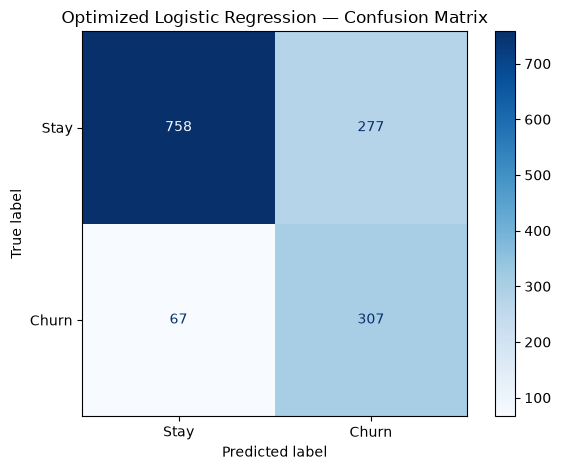

In [214]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Stay", "Churn"],
    cmap="Blues",
    values_format="d"
)

plt.title("Optimized Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()

## 9. Save the trained pipeline

Export the **entire fitted pipeline** with Joblib, not just the Logistic Regression estimator. This preserves the fitted encoder, scaler, and classifier together, so the Streamlit application can accept the same original 19 input features without manual preprocessing.

The saved file is created at `notebooks/model/best_churn_model.joblib` when the notebook is run from its `notebooks/` directory.

In [215]:
import joblib
from pathlib import Path

# Create model directory
model_dir = Path("model")
model_dir.mkdir(parents=True, exist_ok=True)

# Save the complete fitted pipeline
model_path = model_dir / "best_churn_model.joblib"

joblib.dump(best_model, model_path)

print(f"Model saved successfully: {model_path}")

Model saved successfully: model\best_churn_model.joblib


### Verify model serialization

Reload the Joblib file and compare its predictions with the in-memory pipeline. Matching predictions confirm that saving and loading preserved inference behavior for the tested rows.

**Security note:** Load Joblib files only from trusted sources, because deserialization can execute code.

In [216]:
loaded_model = joblib.load(model_path)

# Check that the loaded model produces identical predictions
original_predictions = best_model.predict(X_test)
loaded_predictions = loaded_model.predict(X_test)

assert (original_predictions == loaded_predictions).all()

print("Model loading and prediction verification passed!")

Model loading and prediction verification passed!
